# Configurazione e Caricamento Dati

In [1]:
# Importazione delle Librerie
# Importi tutti i pacchetti necessari (pandas, numpy, matplotlib,
# sklearn per i modelli tradizionali e l'eventuale framework di Deep
# Learning per la regressione sequenziale).
import os
import glob
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split,GroupKFold, StratifiedGroupKFold, GridSearchCV,learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, make_scorer, roc_auc_score, mean_absolute_error, r2_score
from sklearn.svm import SVC, SVR
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier, XGBRegressor
from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt


RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

In [2]:
# Definizione delle Funzioni di Supporto (Igiene del Dato)
# Incolli le funzioni per elaborare i singoli file CSV.
# Qui implementi il downsampling (es. aggregare i dati ogni 10 o 30 secondi
# per togliere il rumore e alleggerire il calcolo) e calcoli la colonna
# fondamentale elapsed_min (i minuti passati dall'inizio del test).

def load_and_resample_battery_csv(file_path, resample_sec=10):
    """
    Reads a single telemetry CSV file, calculates elapsed time, and applies temporal
    downsampling based on a window of seconds (resample_sec).
    """
    # 1. Load the CSV file with the correct separator
    df = pd.read_csv(file_path, sep=';')
    
    # 2. Sequential sorting of the DataFrame based on the 'Tempo' column
    df['Tempo'] = pd.to_datetime(df['Tempo'], utc=True)
    df = df.sort_values('Tempo').reset_index(drop=True)
    
    # 3. Immediate calculation of the native time column (elapsed_min)
    # Indicates how many minutes have passed since the exact start of the test for this specific cell
    df['elapsed_min'] = (df['Tempo'] - df['Tempo'].iloc[0]).dt.total_seconds() / 60.0
    
    # 4. APPLYING DOWNSAMPLING (If requested)
    if resample_sec is not None and resample_sec > 1:
        # Set the timestamp as the temporal index to use Pandas' resample functions
        df = df.set_index('Tempo')
        
        # Aggregate by taking the mean of the physical values in the chosen second window
        # (e.g., if resample_sec=10, 10 rows per second become 1 row which is the mean of the 10)
        df_resampled = df.resample(f'{resample_sec}s').mean()
        
        # Restore the index and correctly recalculate the elapsed time column
        df = df_resampled.reset_index()
        df['elapsed_min'] = (df['Tempo'] - df['Tempo'].iloc[0]).dt.total_seconds() / 60.0
        
    return df

In [3]:
# Caricamento in Memoria dei File CSV Grezzi
# Cicli su tutti i file della cartella, applichi
# la funzione della Cella 2 e salvi i dataframe risultanti
# in un dizionario Python (es. dati_completi = {'nome_file.csv': df}).
# Nota: In questa fase non stai ancora tagliando il tempo, carichi le curve intere.

RAW_CSV_FOLDER = "data\\raw_csvs"

csv_files = sorted(glob.glob(os.path.join(RAW_CSV_FOLDER, "*.csv")))

battery_dict = {}

for file_path in csv_files:
    file_name = os.path.basename(file_path)
    df_clean = load_and_resample_battery_csv(file_path, resample_sec=10)
    if df_clean is not None and len(df_clean) > 0:
        battery_dict[file_name] = df_clean


In [4]:
list_unique_files = list(battery_dict.keys())

file_train_val, file_holdout_test = train_test_split(
    list_unique_files, 
    test_size=0.20, 
    random_state=RANDOM_SEED,
    shuffle=True
)

overlap = set(file_train_val).intersection(set(file_holdout_test))
assert len(overlap) == 0, "ERRORE: Rilevato mescolamento tra i file di Train e di Test!"
print("✓ Sicurezza Anti-Leakage confermata: nessuna sovrapposizione tra i due set.")

✓ Sicurezza Anti-Leakage confermata: nessuna sovrapposizione tra i due set.


# Task 1 - Classificazione Binaria Precoce (PASS/FAIL)

In [5]:
# Estrazione del Target Binario (La Verità)
# Per ogni file, guardi l'ultimo valore registrato di Capacity (Ah).
# Definisci la regola: se $C_{\text{finale}}
# \ge 5\text{ Ah} \implies \text{label} = 1$ (SUCCESS),
# altrimenti $0$ (FAIL). Assegni questa etichetta univoca a ogni file.

summary_train_df = pd.DataFrame(columns=['file_name', 'final_capacity', 'label'])
summary_test_df = pd.DataFrame(columns=['file_name', 'final_capacity', 'label'])

rows_train = []
rows_test = []

for file_name in file_train_val:
    df = battery_dict[file_name]
    final_capacity = df['Capacity (Ah)'].iloc[-1]
    label = 1 if final_capacity >= 5.0 else 0
    rows_train.append({
        'file_name': file_name,
        'final_capacity': final_capacity,
        'label': label
    })

for file_name in file_holdout_test:
    df = battery_dict[file_name]
    final_capacity = df['Capacity (Ah)'].iloc[-1]
    label = 1 if final_capacity >= 5.0 else 0
    rows_test.append({
        'file_name': file_name,
        'final_capacity': final_capacity,
        'label': label
    })

summary_train_df = pd.DataFrame(rows_train)
summary_test_df = pd.DataFrame(rows_test)

In [6]:
# Funzione di Troncamento e Creazione Feature (Una riga per Batteria)
# Definisci una funzione che prende una cella, taglia i dati al minuto
# $W$ (es. $W=60$ o $W=120$) e calcola le feature riassuntive di quella
# finestra (Tensione finale, pendenza/derivata della curva in quell'ora,
# media mobile, capacità accumulata fino a quel momento).
# Restituisce una sola riga per quel file.

def extract_features_from_battery(df, window_minutes=60, starting_minute = 0):
    """
    Extracts features from a battery DataFrame truncated to a specific time window.
    
    Parameters:
    - df: DataFrame containing the battery telemetry data.
    - window_minutes: The time window in minutes to truncate the data.
    - starting_minute: The starting minute from which to begin truncation.
    
    Returns:
    - A dictionary of extracted features.
    """
    # Truncate the DataFrame to the specified time window
    truncated_df = df[(df['elapsed_min'] >= starting_minute) & (df['elapsed_min'] <= starting_minute + window_minutes)]
    
    # Calculate features
    delta_voltage = truncated_df['Tensione (V)'].iloc[-1] - truncated_df['Tensione (V)'].iloc[0] if len(truncated_df) > 1 else np.nan
    dv_dt = delta_voltage / window_minutes if not np.isnan(delta_voltage) else np.nan
    d2v_dt2 = (truncated_df['Tensione (V)'].iloc[-1] - 2 * truncated_df['Tensione (V)'].iloc[len(truncated_df)//2] + truncated_df['Tensione (V)'].iloc[0]) / (window_minutes**2) if len(truncated_df) > 2 else np.nan
    v_mean = truncated_df['Tensione (V)'].mean() if not truncated_df.empty else np.nan
    v_std = truncated_df['Tensione (V)'].std() if not truncated_df.empty else np.nan
    delta_C = truncated_df['Capacity (Ah)'].iloc[0] - truncated_df['Capacity (Ah)'].iloc[-1] if len(truncated_df) > 1 else np.nan
    dC_dt = delta_C / window_minutes if not np.isnan(delta_C) else np.nan
    d2C_dt2 = (truncated_df['Capacity (Ah)'].iloc[-1] - 2 * truncated_df['Capacity (Ah)'].iloc[len(truncated_df)//2] + truncated_df['Capacity (Ah)'].iloc[0]) / (window_minutes**2) if len(truncated_df) > 2 else np.nan
    v_start = truncated_df['Tensione (V)'].iloc[0] if not truncated_df.empty else np.nan
    v_end = truncated_df['Tensione (V)'].iloc[-1] if not truncated_df.empty else np.nan
    c_start = truncated_df['Capacity (Ah)'].iloc[0] if not truncated_df.empty else np.nan
    c_end = truncated_df['Capacity (Ah)'].iloc[-1] if not truncated_df.empty else np.nan
    
    return {
        'start_time': starting_minute,
        'end_time': starting_minute + window_minutes,
        'delta_voltage': delta_voltage,
        'dv_dt': dv_dt,
        'd2v_dt2': d2v_dt2,
        'mean_voltage': v_mean,
        'std_voltage': v_std,
        'delta_capacity': delta_C,
        'dC_dt': dC_dt,
        'd2C_dt2': d2C_dt2,
        'voltage_start': v_start,
        'voltage_end': v_end,
        'capacity_start': c_start,
        'capacity_end': c_end
    }

In [7]:
# Configurazione dello Schema di Validazione (GroupKFold)
# Incolli la tua funzione di validazione
# Configura un GroupKFold a 5 fold basato sull'ID del file.
# All'interno del ciclo dei fold inserisci una Pipeline con lo StandardScaler()
# e il modello (es. RandomForestClassifier o LogisticRegression(max_iter=300)).

#WINDOW_TARGET = [30,60,90,120,150,180,210,240,270,300]
FINESTRE_START_TEST = [0,30,60,90,120,150,180,210,240,270]
FINESTRE_TEST = [30,60,90,120,150,180,210,240,270,300]
features_train_list = []
features_test_list = []

for file_name in file_train_val:
    df_train = battery_dict[file_name]
    for i in range(len(FINESTRE_START_TEST)):
        features_train = extract_features_from_battery(df_train, window_minutes=FINESTRE_TEST[i], starting_minute=FINESTRE_START_TEST[i])
        features_train['file_name'] = file_name
        features_train['window'] = FINESTRE_TEST[i]
        features_train_list.append(features_train)

for file_name in file_holdout_test:
    df_test = battery_dict[file_name]
    for i in range(len(FINESTRE_START_TEST)):
        features_test = extract_features_from_battery(df_test, window_minutes=FINESTRE_TEST[i], starting_minute=FINESTRE_START_TEST[i])
        features_test['file_name'] = file_name
        features_test['window'] = FINESTRE_TEST[i]
        features_test_list.append(features_test)

df_classification_train = pd.DataFrame(features_train_list)
df_classification_test = pd.DataFrame(features_test_list)
print(f"✓ Matrice di addestramento creata!")
print(f"  - Dimensioni totali: {df_classification_train.shape[0]} righe, {df_classification_train.shape[1]} colonne.")
print(f"  - Numero di righe medio per batteria: {df_classification_train.shape[0] / len(file_train_val):.1f}")

✓ Matrice di addestramento creata!
  - Dimensioni totali: 500 righe, 16 colonne.
  - Numero di righe medio per batteria: 10.0


In [8]:
# Ciclo Sperimentale "ROC-AUC over Time" (Il Training e Validazione)
# Fai girare un ciclo for sulle finestre temporali che vuoi testare
# (es. 15min, 30min, 60min, 120min). Per ogni finestra, crei la matrice
# delle feature usando la Cella 6 (solo sui file di Train) e chiami la
# validazione della Cella 7. Salvi i punteggi di ROC-AUC Out-of-Fold.

def evaluate_model_on_window(df_matrix, model, n_splits=3):
    """
    [METODO DI TRAIN & TEST IN CV]
    Esegue lo scaling, l'addestramento e il test out-of-fold dei modelli 
    sulla matrice generata con il tuo metodo di estrazione feature.
    """
    # Colonne di metadati o target da escludere tassativamente dal fit dei modelli
    exclude_cols = {'file_name', 'label', 'start_time', 'end_time'}
    feature_cols = [c for c in df_matrix.columns if c not in exclude_cols]
    
    X = df_matrix[feature_cols].values
    y = df_matrix['label'].values
    groups = df_matrix['file_name'].values
    
    if len(np.unique(groups)) < n_splits or len(np.unique(y)) < 2:
        return np.nan
        
    sgkf = StratifiedGroupKFold(n_splits=n_splits)
    pipeline = Pipeline([('scaler', StandardScaler()), ('clf', model)])
    
    oof_preds = np.zeros(len(df_matrix))
    
    for train_idx, val_idx in sgkf.split(X, y, groups):
        # FASE DI TRAINING
        pipeline.fit(X[train_idx], y[train_idx])
        
        # FASE DI TEST (Validazione Interna Out-of-Fold)
        if hasattr(pipeline, 'predict_proba'):
            oof_preds[val_idx] = pipeline.predict_proba(X[val_idx])[:, 1]
        else:
            oof_preds[val_idx] = pipeline.decision_function(X[val_idx])
            
    return roc_auc_score(y, oof_preds)

In [9]:
# Generazione del Grafico di Classificazione Precoce
# Plotti le curve di ROC-AUC dei modelli rispetto ai minuti passati
# (Asse X = Minuti, Asse Y = ROC-AUC). Questo grafico dimostra visivamente
# dopo quanti minuti lo spazio delle feature diventa separabile.

# 1. Configurazione della griglia temporale di cut-off (da t=0 fino a W minuti)
# FINESTRE_START_TEST = [0,0,0,0,0,0,0,0,0,0]


modelli = {
        "Logistic Regression": LogisticRegression(
        solver='liblinear', class_weight='balanced',
        max_iter=1000, random_state=RANDOM_SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=8, class_weight='balanced',
        n_jobs=-1, random_state=RANDOM_SEED
    ),    
    "SVM": CalibratedClassifierCV(
        estimator=SVC(
            kernel='rbf',        # maps data to infinite-dimensional space (Gaussian kernel)
            C=1.0,               # regularization
            gamma='scale',       # 1 / (n_features * X.var()) — good default
            class_weight='balanced',
            random_state=RANDOM_SEED
        ),
        method='sigmoid',        # Platt scaling (standard for SVMs)
        cv=3,                    # 3-fold internal cross-validation for calibration
        ensemble=False           # trains a single final SVC on the full dataset
    ),
    "XGBoost": XGBClassifier(
        n_estimators=100, max_depth=4, learning_rate=0.05,
        n_jobs=-1, eval_metric='logloss', random_state=RANDOM_SEED
    ),
    "MLP": MLPClassifier(
        hidden_layer_sizes=(64, 32), activation='relu', solver='adam',
        alpha=0.01, max_iter=300, early_stopping=True, random_state=RANDOM_SEED
    ),
    }

def evaluate_models(
        models, 
        window_start, 
        window_end,
        battery_dict, 
        summary_train_df, 
        file_train_val):
    
    storico_risultati = {name: [] for name in models.keys()}

    # 2. Ciclo principale di estrazione e validazione
    for i in range(len(window_start)):
        records_finestra = []
        w_end = window_end[i]
        w_start = window_start[i]
        
        for file_name in file_train_val:
            df_bat = battery_dict[file_name] # Usa il nome del tuo dizionario in memoria
            label = summary_train_df[summary_train_df['file_name'] == file_name]['label'].values[0]
            
            # Invocazione del TUO metodo nativo: partiamo da 0 e analizziamo un'ampiezza di 'w' minuti
            feat_dict = extract_features_from_battery(df_bat, window_minutes=w_end, starting_minute=w_start)
            
            # Se la serie contiene dati validi e non NaNs bloccanti
            if feat_dict is not None and not np.isnan(feat_dict['delta_voltage']):
                feat_dict['label'] = label
                feat_dict['file_name'] = file_name
                records_finestra.append(feat_dict)
                
        if not records_finestra:
            for name in models.keys(): storico_risultati[name].append(np.nan)
            continue
            
        # Convertiamo la lista di dizionari generata dal tuo metodo in un DataFrame pulito
        df_matrice_w = pd.DataFrame(records_finestra)
        
        # Riempiamo eventuali buchi di calcolo per le derivate seconde (bfill/ffill di sicurezza d'esame)
        df_matrice_w = df_matrice_w.bfill().ffill()
        
        # Valutazione
        for name, model in models.items():
            auc_score = evaluate_model_on_window(df_matrice_w, model)
            storico_risultati[name].append(auc_score)
            #print(f"Cut-off {w_start:3d}-{w_end:3d} min | Modello: {name:20s} | CV ROC-AUC: {auc_score:.4f}")

    return storico_risultati

storico_risultati = evaluate_models(
    models=modelli,
    window_start=FINESTRE_START_TEST,
    window_end=FINESTRE_TEST,
    battery_dict=battery_dict,
    summary_train_df=summary_train_df,
    file_train_val=file_train_val)
    

In [10]:
# Test Finale (Holdout) della Classificazione
# Scegli il modello migliore e la finestra ottimale (es. 60 minuti).
# Alleni il modello sull'intero set di Training (0-60 min).
# Prendi i file di Test messi da parte nella Cella 4, li tronchi a 60 minuti,
# estrai le feature e fai la predizione finale. Generi la Matrice di Confusione
# per l'esame.

def plot_roc_auc_over_time(storico_risultati, finestre_test):
    """
    Plots the ROC-AUC scores over time for different models.
    
    Parameters:
    - storico_risultati: Dictionary containing model names as keys and lists of ROC-AUC scores as values.
    - finestre_test: List of time windows corresponding to the ROC-AUC scores.
    """
    plt.figure(figsize=(10, 6))

    for name, scores in storico_risultati.items():
        plt.plot(finestre_test, scores, marker='o', lw=2, label=name)

    plt.axhline(0.90, color='r', linestyle='--', alpha=0.6, label='Soglia di Accettabilità Industriale (0.90)')
    plt.title("Evoluzione della Separabilità Precoce (Task Classificazione Binaria)")
    plt.xlabel("Tempo di Osservazione Parziale (Minuti dall'inizio della scarica)")
    plt.ylabel("Mean Out-of-Fold ROC-AUC")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

In [11]:

# Usiamo la finestra ottimale emersa dai tuoi test (es. 60 minuti)
START_WINDOW = 60
END_WINDOW = 90

exclude_cols = {'label', 'file_name', 'start_time', 'end_time'}

# 1. Costruzione della matrice di Train per il Tuning
train_records = []
for file_name in file_train_val:
    df_bat = battery_dict[file_name]
    label = summary_train_df[summary_train_df['file_name'] == file_name]['label'].values[0]
    feat = extract_features_from_battery(df_bat, window_minutes=END_WINDOW, starting_minute=START_WINDOW)
    if feat is not None and not np.isnan(feat['delta_voltage']):
        feat['file_name'] = file_name
        feat['label'] = label
        train_records.append(feat)
        
df_tuning = pd.DataFrame(train_records).bfill().ffill()
feature_names = [c for c in df_tuning.columns if c not in exclude_cols]

X_train = df_tuning[feature_names].values
y_train = df_tuning['label'].values
groups_train = df_tuning['file_name'].values

# 2. Definizione delle "Griglie" di parametri per ciascun modello
# NOTA: Usando la Pipeline, dobbiamo anteporre 'clf__' ai nomi dei parametri!
param_grids = {
    "Logistic Regression": {
        'clf__C': [0.01, 0.1, 1.0, 10.0],
        'clf__l1_ratio': [0.0, 1.0]
    },
    "Random Forest": {
        'clf__n_estimators': [50, 100, 200],
        'clf__max_depth': [4, 6, 8, 12],
        'clf__min_samples_split': [2, 5]
    },
    "SVM": {
        # Per la SVM calibrata, dobbiamo entrare dentro l'estimator specficiando 'clf__estimator__'
        'clf__estimator__C': [0.1, 1.0, 10.0],
        'clf__estimator__kernel': ['linear', 'rbf'],
        'clf__estimator__gamma': ['scale', 'auto']
    },
    "XGBoost": {
        'clf__n_estimators': [50, 100, 150],
        'clf__max_depth': [3, 4, 6],
        'clf__learning_rate': [0.01, 0.05, 0.1]
    },
    "MLP": {
        'clf__hidden_layer_sizes': [(32, 16), (64, 32), (64, 64)],
        'clf__alpha': [0.001, 0.01, 0.1]
    }
}

# Dizionario dove salveremo i modelli ottimizzati pronti per il test set finale
modelli_ottimizzati = {}

# 3. Ciclo di ottimizzazione
sgkf = StratifiedGroupKFold(n_splits=5)

for name, model_instance in modelli.items():   
    # Creiamo la pipeline standardizzata
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', model_instance)
    ])
    
    # Configuriaramo il GridSearch con StratifiedGroupKFold e scoring basato su ROC-AUC
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        cv=sgkf,
        scoring='roc_auc',
        n_jobs=-1,
        verbose=1
    )
    
    # Eseguiamo il fit passando esplicitamente i gruppi (i nomi dei file delle batterie)
    grid_search.fit(X_train, y_train, groups=groups_train)
    
    # Salviamo il modello migliore (già ri-addestrato su tutto X_train con i parametri ottimi)
    modelli_ottimizzati[name] = grid_search.best_estimator_

optimized_results = evaluate_models(
    models=modelli_ottimizzati,
    window_start=FINESTRE_START_TEST,
    window_end=FINESTRE_TEST,
    battery_dict=battery_dict,
    summary_train_df=summary_train_df,
    file_train_val=file_train_val
)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Fitting 5 folds for each of 27 candidates, totalling 135 fits


c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Fitting 5 folds for each of 9 candidates, totalling 45 fits


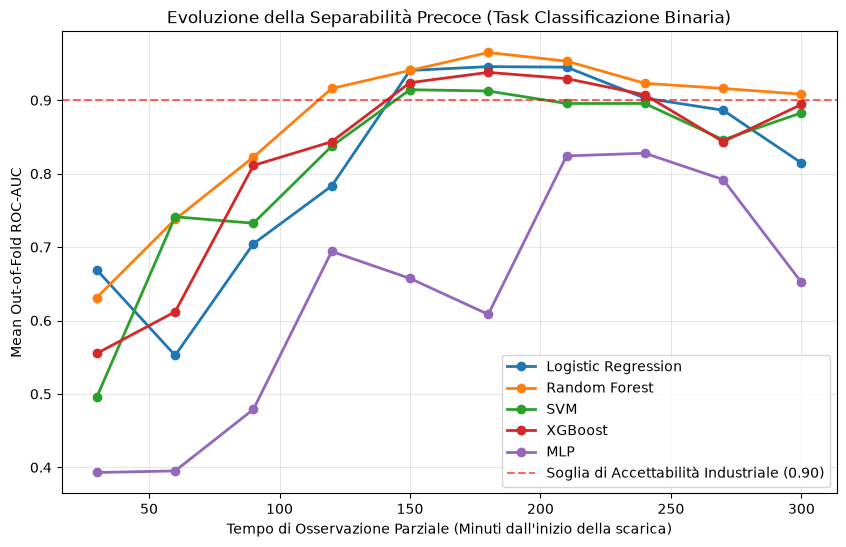

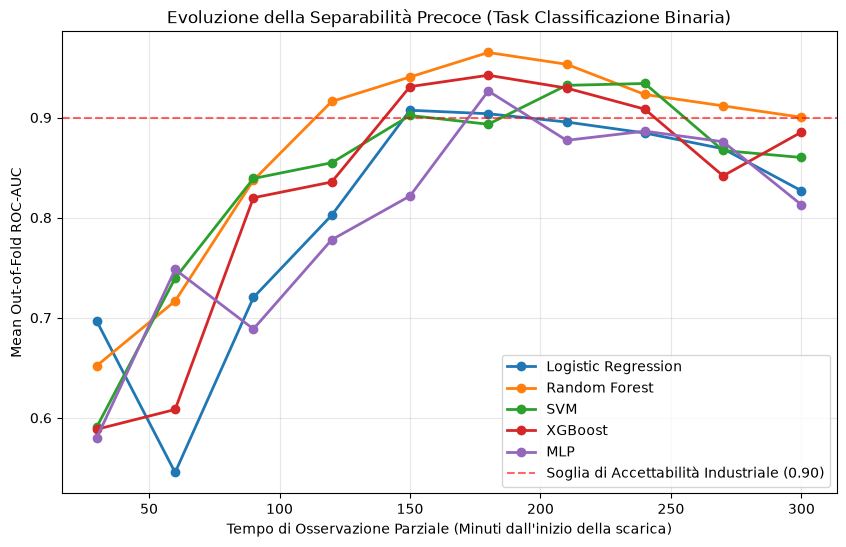

In [12]:
plot_roc_auc_over_time(storico_risultati, FINESTRE_TEST)
plot_roc_auc_over_time(optimized_results, FINESTRE_TEST)

              precision    recall  f1-score   support

        FAIL       1.00      0.80      0.89         5
     SUCCESS       0.89      1.00      0.94         8

    accuracy                           0.92        13
   macro avg       0.94      0.90      0.92        13
weighted avg       0.93      0.92      0.92        13



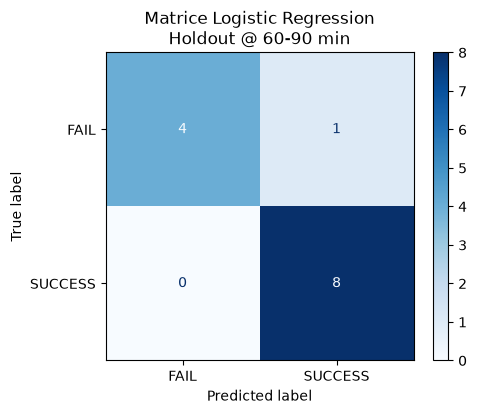

              precision    recall  f1-score   support

        FAIL       0.67      0.80      0.73         5
     SUCCESS       0.86      0.75      0.80         8

    accuracy                           0.77        13
   macro avg       0.76      0.78      0.76        13
weighted avg       0.78      0.77      0.77        13



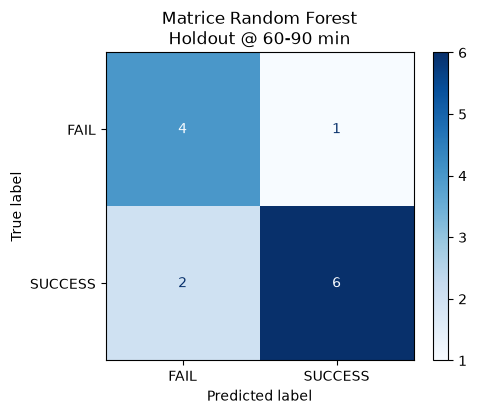

              precision    recall  f1-score   support

        FAIL       1.00      0.80      0.89         5
     SUCCESS       0.89      1.00      0.94         8

    accuracy                           0.92        13
   macro avg       0.94      0.90      0.92        13
weighted avg       0.93      0.92      0.92        13



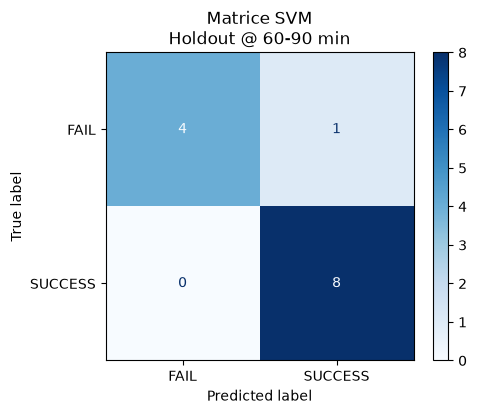

              precision    recall  f1-score   support

        FAIL       0.80      0.80      0.80         5
     SUCCESS       0.88      0.88      0.88         8

    accuracy                           0.85        13
   macro avg       0.84      0.84      0.84        13
weighted avg       0.85      0.85      0.85        13



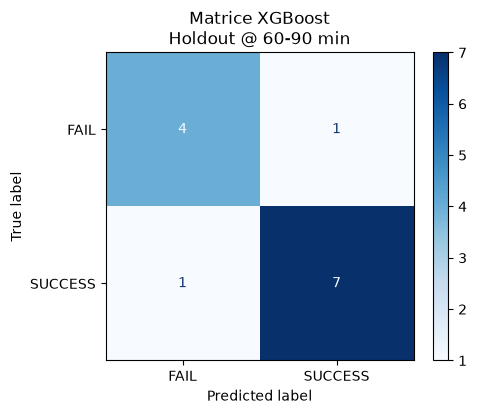

              precision    recall  f1-score   support

        FAIL       1.00      0.80      0.89         5
     SUCCESS       0.89      1.00      0.94         8

    accuracy                           0.92        13
   macro avg       0.94      0.90      0.92        13
weighted avg       0.93      0.92      0.92        13



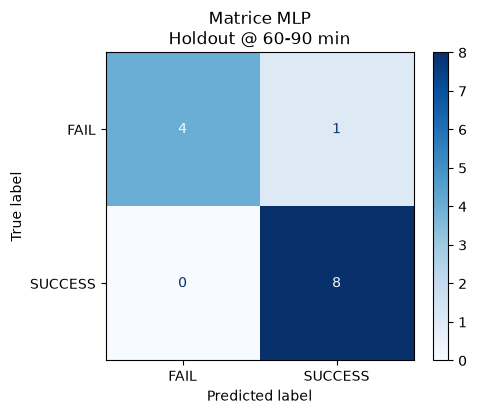

In [13]:
# ==========================================
# CELLA 10: TEST FINALE DINAMICO SU TUTTI I MODELLI (HOLDOUT SET)
# ==========================================
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

exclude_cols = {'label', 'file_name', 'start_time', 'end_time'}

# 1. Preparazione dell'intero Training Set alla finestra stabilita
train_records = []
for file_name in file_train_val:
    df_bat = battery_dict[file_name]
    label = summary_train_df[summary_train_df['file_name'] == file_name]['label'].values[0]
    
    # Invocazione del tuo metodo nativo
    feat = extract_features_from_battery(df_bat, window_minutes=END_WINDOW, starting_minute=START_WINDOW)
    if feat is not None and not np.isnan(feat['delta_voltage']):
        feat['label'] = label
        train_records.append(feat)
        
df_train_final = pd.DataFrame(train_records).bfill().ffill()
feature_names = [c for c in df_train_final.columns if c not in exclude_cols]

X_train_f = df_train_final[feature_names].values
y_train_f = df_train_final['label'].values


# 2. Preparazione dell'Holdout Test Set (Dati mai visti, sigillati all'inizio)
test_records = []
for file_name in file_holdout_test:
    df_bat = battery_dict[file_name]
    label = summary_test_df[summary_test_df['file_name'] == file_name]['label'].values[0]
    
    feat = extract_features_from_battery(df_bat, window_minutes=END_WINDOW, starting_minute=START_WINDOW)
    if feat is not None and not np.isnan(feat['delta_voltage']):
        feat['label'] = label
        test_records.append(feat)
        
df_test_final = pd.DataFrame(test_records).bfill().ffill()

X_test_f = df_test_final[feature_names].values
y_test_f = df_test_final['label'].values


# 3. Ciclo dinamico di Fit e Test su ogni modello configurato
for name, model_instance in modelli_ottimizzati.items():
    
    # Creiamo una pipeline fresca per il modello corrente per garantire lo scaling isolato
    pipeline_definitiva = Pipeline([
        ('scaler', StandardScaler()), 
        ('clf', model_instance)
    ])
    
    # --- FIT GLOBAL SUL TRAIN SET ---
    pipeline_definitiva.fit(X_train_f, y_train_f)
    
    # --- PREDDIZIONE SULL'HOLDOUT SET ---
    y_pred_f = pipeline_definitiva.predict(X_test_f)
    
    # Stampa dei risultati testuali (Precision, Recall, F1-Score)
    print(classification_report(y_test_f, y_pred_f, target_names=['FAIL', 'SUCCESS']))
    
    # Generazione e visualizzazione della Matrice di Confusione
    cm = confusion_matrix(y_test_f, y_pred_f)
    fig, ax = plt.subplots(figsize=(5, 4))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['FAIL', 'SUCCESS'])
    disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
    plt.title(f"Matrice {name}\nHoldout @ {START_WINDOW}-{END_WINDOW} min")
    plt.show()

In [14]:
def plot_learning_curve(
        models_to_analyze,
        X_train,
        y_train,
        groups_train):
    
    for model_name, model_to_analyze in models_to_analyze.items():
        sgkf = StratifiedGroupKFold(n_splits=3)
        train_sizes, train_scores, test_scores = learning_curve(
            estimator=model_to_analyze,
            X=X_train,
            y=y_train,
            groups=groups_train,
            train_sizes=np.linspace(0.2, 1.0, 5),
            cv=sgkf,
            scoring='roc_auc',
            n_jobs=-1,
            random_state=RANDOM_SEED
        )
        train_mean = np.mean(train_scores, axis=1)
        train_std = np.std(train_scores, axis=1)
        test_mean = np.mean(test_scores, axis=1)
        test_std = np.std(test_scores, axis=1)

        plt.figure(figsize=(10, 6))
        plt.plot(train_sizes, train_mean, color='blue', marker='o', markersize=5, label='Training ROC-AUC')
        plt.fill_between(train_sizes, train_mean + train_std, train_mean - train_std, alpha=0.15, color='blue')

        plt.plot(train_sizes, test_mean, color='green', linestyle='--', marker='s', markersize=5, label='Validation ROC-AUC (CV)')
        plt.fill_between(train_sizes, test_mean + test_std, test_mean - test_std, alpha=0.15, color='green')

        plt.title("Learning Curves - Modello: {}".format(model_name))
        plt.xlabel("Numero di campioni (Batterie) usati nel Training")
        plt.ylabel("Punteggio ROC-AUC")
        plt.grid(True, alpha=0.3)
        plt.legend(loc='lower right')
        plt.show()

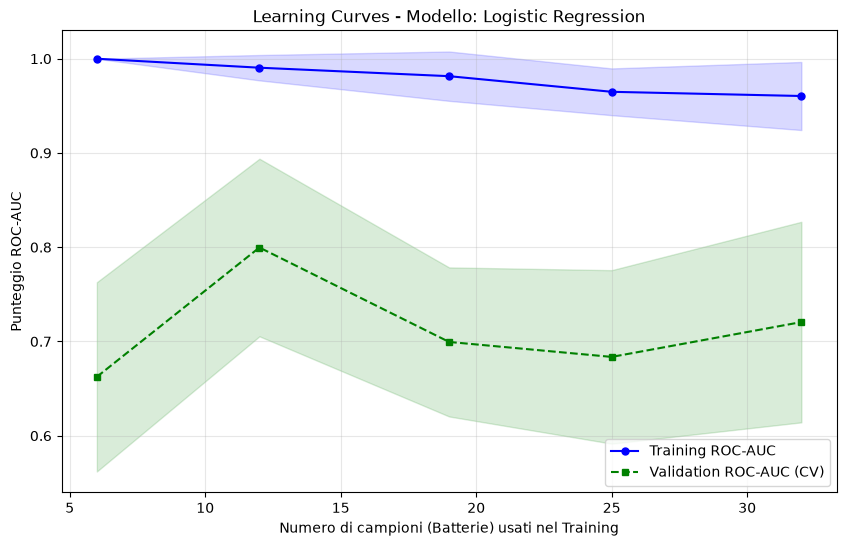

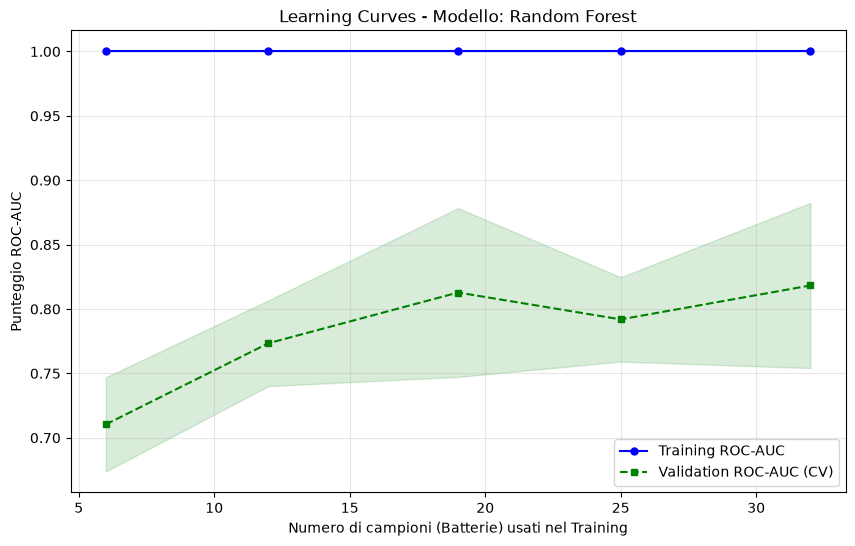

c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
3 fits failed out of a total of 15.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
3 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\model_selection\_validation.py", line 856, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklear

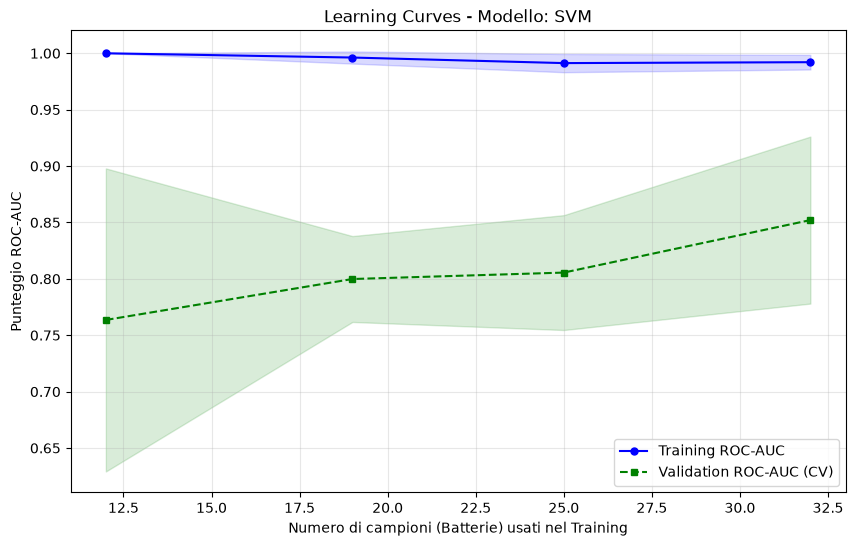

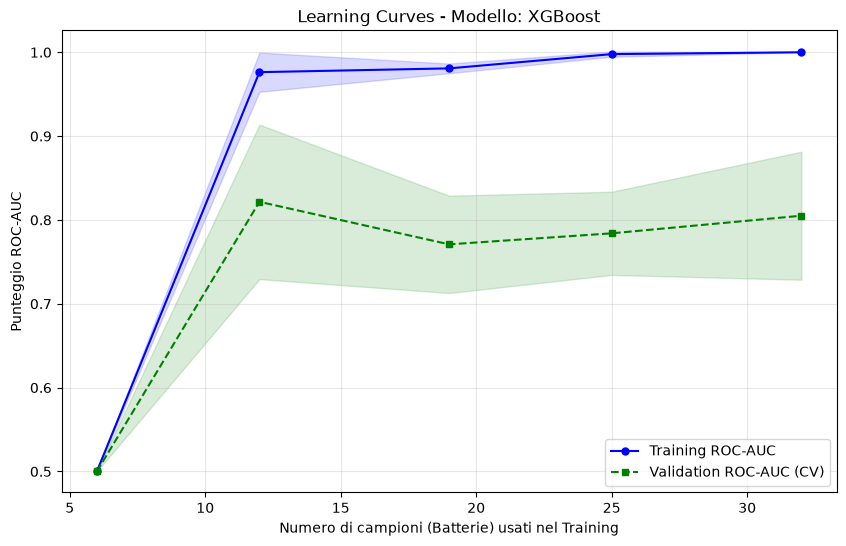

c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
3 fits failed out of a total of 15.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
2 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\model_selection\_validation.py", line 856, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklear

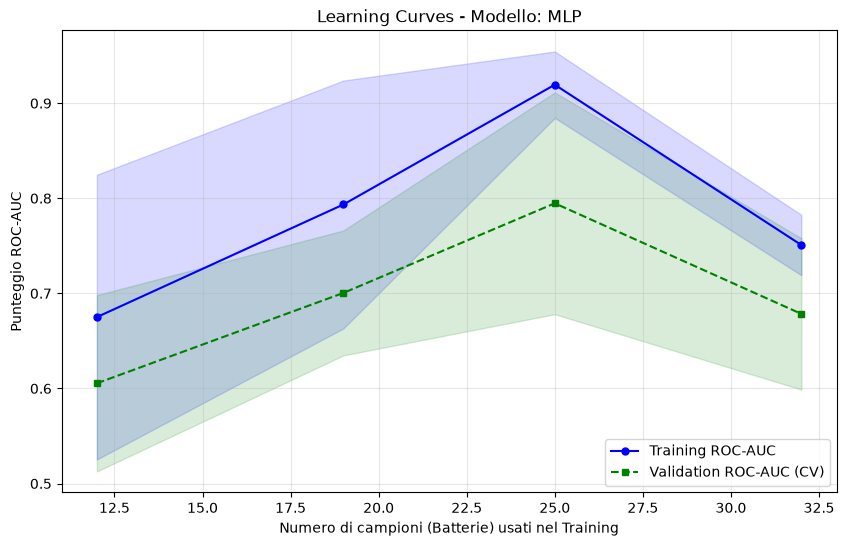

In [15]:
plot_learning_curve(
    models_to_analyze=modelli_ottimizzati,
    X_train=X_train_f,
    y_train=y_train_f,
    groups_train=groups_train
)

# Task 2 - Regressione Precoce (Stima della Capacità Esatta)

## Regression with Machine Learning Models

In [ ]:
# aggregation by step of 10 minutes

# Configurazione della finestra critica e dei blocchi storici a ritroso
MINUTO_FINE_OSSERVAZIONE = 500
AMPIEZZA_BLOCCO_MINUTI = 20
NUMERO_LAG = 4  # Genera i blocchi temporali: t (80-90), t-1 (70-80), t-2 (60-70), t-3 (60-70)

# Sostituisci con il nome reale della colonna della capacità finale nel tuo summary_df
COLONNA_TARGET_Y = 'final_capacity' 

def extract_regression_lagged_features(df, base_window_min=10, steps=3, end_minute=90):
    """
    Estrae le feature fisiche aggregando i dati in blocchi temporali a ritroso.
    Restituisce un unico dizionario piatto con le feature laggate (_t, _t-1, _t-2, _t-3).
    """
    all_features = {}
    
    for step in range(steps):
        # Calcolo dei confini temporali del blocco corrente
        w_start = end_minute - (step + 1) * base_window_min
        w_end = end_minute - step * base_window_min
        
        if w_start < 0:
            break
            
        # Filtriamo il subset temporale del CSV della singola batteria
        truncated_df = df[(df['elapsed_min'] >= w_start) & (df['elapsed_min'] <= w_end)]
        
        # Controllo di sicurezza se mancano record nel blocco
        if len(truncated_df) < 2:
            return None 
            
        # Calcolo delle pendenze fisiche e medie sul blocco
        delta_voltage = truncated_df['Tensione (V)'].iloc[-1] - truncated_df['Tensione (V)'].iloc[0]
        dv_dt = delta_voltage / base_window_min
        v_mean = truncated_df['Tensione (V)'].mean()
        v_std = truncated_df['Tensione (V)'].std()
        
        delta_C = truncated_df['Capacity (Ah)'].iloc[0] - truncated_df['Capacity (Ah)'].iloc[-1]
        dC_dt = delta_C / base_window_min
        
        v_start = truncated_df['Tensione (V)'].iloc[0]
        v_end = truncated_df['Tensione (V)'].iloc[-1]
        c_end = truncated_df['Capacity (Ah)'].iloc[-1]
        
        # Suffisso identificativo del ritardo temporale
        suffix = f"_t" if step == 0 else f"_t-{step}"
        
        # Mappatura delle feature
        all_features[f'dv_dt{suffix}'] = dv_dt
        all_features[f'mean_voltage{suffix}'] = v_mean
        all_features[f'std_voltage{suffix}'] = v_std
        all_features[f'dC_dt{suffix}'] = dC_dt
        all_features[f'voltage_start{suffix}'] = v_start
        all_features[f'voltage_end{suffix}'] = v_end
        all_features[f'capacity_end{suffix}'] = c_end

    return all_features

# --- 1. ESTRAZIONE TRAIN / VALIDATION DATASET ---
train_regression_records = []
for file_name in file_train_val:
    df_bat = battery_dict[file_name]
    # Recuperiamo il valore continuo della capacità reale dal summary
    y_val = summary_train_df[summary_train_df['file_name'] == file_name][COLONNA_TARGET_Y].values[0]
    
    feat_reg = extract_regression_lagged_features(
        df_bat, base_window_min=AMPIEZZA_BLOCCO_MINUTI, steps=NUMERO_LAG, end_minute=MINUTO_FINE_OSSERVAZIONE
    )
    
    if feat_reg is not None:
        feat_reg['file_name'] = file_name
        feat_reg['target_capacity'] = y_val  # Nuovo target Continuo (Y)
        train_regression_records.append(feat_reg)

df_reg_train = pd.DataFrame(train_regression_records).bfill().ffill()

# --- 2. ESTRAZIONE HOLDOUT TEST DATASET ---
test_regression_records = []
for file_name in file_holdout_test:
    df_bat = battery_dict[file_name]
    y_val = summary_test_df[summary_test_df['file_name'] == file_name][COLONNA_TARGET_Y].values[0]
    
    feat_reg = extract_regression_lagged_features(
        df_bat, base_window_min=AMPIEZZA_BLOCCO_MINUTI, steps=NUMERO_LAG, end_minute=MINUTO_FINE_OSSERVAZIONE
    )
    
    if feat_reg is not None:
        feat_reg['file_name'] = file_name
        feat_reg['target_capacity'] = y_val
        test_regression_records.append(feat_reg)

df_reg_test = pd.DataFrame(test_regression_records).bfill().ffill()

# --- 3. ISOLAMENTO DELLE MATRICI NDARRAY PER SCIKIT-LEAR ---
exclude_reg_cols = {'target_capacity', 'file_name', 'start_time', 'end_time', 'label'}
feature_reg_names = [c for c in df_reg_train.columns if c not in exclude_reg_cols]

X_train_r = df_reg_train[feature_reg_names].values
y_train_r = df_reg_train['target_capacity'].values
groups_train_r = df_reg_train['file_name'].values

X_test_r = df_reg_test[feature_reg_names].values
y_test_r = df_reg_test['target_capacity'].values

print(f"✓ Dataset Regressione pronto!")
print(f"-> Matrice Train: {X_train_r.shape[0]} batterie, {X_train_r.shape[1]} feature laggate.")
print(f"-> Matrice Test:  {X_test_r.shape[0]} batterie.")

✓ Dataset Regressione pronto!
-> Matrice Train: 49 batterie, 28 feature laggate.
-> Matrice Test:  12 batterie.


In [96]:
modelli_regressione = {
    "Random Forest Regressor": RandomForestRegressor(random_state=RANDOM_SEED, n_jobs=-1),
    "XGBoost Regressor": XGBRegressor(random_state=RANDOM_SEED, n_jobs=-1, eval_metric='rmse'),
    "Support Vector Regressor (SVR)": SVR()
}

# Griglie di iperparametri specifiche per compiti di regressione
param_grids_regression = {
    "Random Forest Regressor": {
        'clf__n_estimators': [50, 100, 200],
        'clf__max_depth': [4, 6, 8],
        'clf__min_samples_leaf': [1, 3, 5]
    },
    "XGBoost Regressor": {
        'clf__n_estimators': [50, 100, 150],
        'clf__max_depth': [3, 4, 5],
        'clf__learning_rate': [0.01, 0.05, 0.1]
    },
    "Support Vector Regressor (SVR)": {
        'clf__C': [0.1, 1.0, 10.0, 50.0],
        'clf__kernel': ['linear', 'rbf'],
        'clf__gamma': ['scale', 'auto']
    }
}

In [97]:
'''def tune_regression_models_on_window(cut_off_minute, battery_dict, summary_train_df, file_train_val):
    """
    Estrae le feature fino al cut_off_minute richiesto ed effettua il tuning
    iperparametrico basato su GroupKFold (ottimizzando l'MSE).
    """
    print(f"\n" + "="*70)
    # Calcolo dinamico: se inserisci 120, estrae la storia a ritroso da lì
    print(f" AVVIO TUNING REGRESSIONE - DATI DISPONIBILI FINO AL MINUTO: {cut_off_minute}")
    print("="*70)
    
    # 1. Estrazione dinamica delle feature storiche basate sul cut-off
    records_tuning = []
    for file_name in file_train_val:
        df_bat = battery_dict[file_name]
        # Recuperiamo il valore reale continuo della capacità
        y_val = summary_train_df[summary_train_df['file_name'] == file_name]['final_capacity'].values[0]
        
        # Estrattore a blocchi di 10 minuti (definito nel passaggio precedente)
        feat_reg = extract_regression_lagged_features(
            df_bat, base_window_min=10, steps=3, end_minute=cut_off_minute
        )
        
        if feat_reg is not None:
            feat_reg['file_name'] = file_name
            feat_reg['target_capacity'] = y_val
            records_tuning.append(feat_reg)
            
    if not records_tuning:
        print(f"❌ Errore: Nessun dato estratto per il minuto {cut_off_minute}. Controlla la lunghezza dei CSV.")
        return None
        
    df_tuning_r = pd.DataFrame(records_tuning).bfill().ffill()
    exclude_cols = {'target_capacity', 'file_name', 'start_time', 'end_time', 'label'}
    feature_names = [c for c in df_tuning_r.columns if c not in exclude_cols]
    
    X_train = df_tuning_r[feature_names].values
    y_train = df_tuning_r['target_capacity'].values
    groups_train = df_tuning_r['file_name'].values
    
    # 2. Ciclo di ottimizzazione sui 3 modelli scelti
    modelli_reg_ottimizzati = {}
    gkf = GroupKFold(n_splits=5)
    
    for name, model_instance in modelli_regressione.items():
        print(f"\nTuning in corso per {name}...")
        
        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('clf', model_instance)
        ])
        
        # GridSearch tarato sul Mean Squared Error
        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grids_regression[name],
            cv=gkf,
            scoring='neg_mean_squared_error', # Ottimizziamo l'errore quadratico
            n_jobs=-1,
            verbose=0
        )
        
        grid_search.fit(X_train, y_train, groups=groups_train)
        
        # Convertiamo il punteggio negativo in RMSE reale (radice dell'errore quadratico) per facilità di lettura
        best_rmse = np.sqrt(-grid_search.best_score_)
        
        print(f" -> Migliori Parametri: {grid_search.best_params_}")
        print(f" -> Miglior RMSE medio in CV: {best_rmse:.4f} Ah")
        
        modelli_reg_ottimizzati[name] = grid_search.best_estimator_
        
    return modelli_reg_ottimizzati, feature_names'''

'def tune_regression_models_on_window(cut_off_minute, battery_dict, summary_train_df, file_train_val):\n    """\n    Estrae le feature fino al cut_off_minute richiesto ed effettua il tuning\n    iperparametrico basato su GroupKFold (ottimizzando l\'MSE).\n    """\n    print(f"\n" + "="*70)\n    # Calcolo dinamico: se inserisci 120, estrae la storia a ritroso da lì\n    print(f" AVVIO TUNING REGRESSIONE - DATI DISPONIBILI FINO AL MINUTO: {cut_off_minute}")\n    print("="*70)\n    \n    # 1. Estrazione dinamica delle feature storiche basate sul cut-off\n    records_tuning = []\n    for file_name in file_train_val:\n        df_bat = battery_dict[file_name]\n        # Recuperiamo il valore reale continuo della capacità\n        y_val = summary_train_df[summary_train_df[\'file_name\'] == file_name][\'final_capacity\'].values[0]\n        \n        # Estrattore a blocchi di 10 minuti (definito nel passaggio precedente)\n        feat_reg = extract_regression_lagged_features(\n            df_ba

In [67]:
# Lancio del tuning impostando la finestra temporale desiderata (es. 150 minuti)
'''MINUTI_OSSERVAZIONE = 150

modelli_reg_ottimi, feature_reg_selezionate = tune_regression_models_on_window(
    cut_off_minute=MINUTI_OSSERVAZIONE,
    battery_dict=battery_dict,
    summary_train_df=summary_train_df,
    file_train_val=file_train_val
)'''

'MINUTI_OSSERVAZIONE = 150\n\nmodelli_reg_ottimi, feature_reg_selezionate = tune_regression_models_on_window(\n    cut_off_minute=MINUTI_OSSERVAZIONE,\n    battery_dict=battery_dict,\n    summary_train_df=summary_train_df,\n    file_train_val=file_train_val\n)'

In [98]:
# Liste per salvare i punteggi da plottare
nomi_modelli = []
rmse_train_list = []
rmse_val_list = []

# NOTA OTTIMIZZATA: Per integrarlo direttamente nel tuo flusso attuale, ecco la funzione di tuning 
# modificata che sputa fuori il grafico di Overfitting/Underfitting automaticamente:

def tune_and_diagnose_regression(cut_off_minute, battery_dict, summary_train_df, file_train_val):
    records_tuning = []
    for file_name in file_train_val:
        df_bat = battery_dict[file_name]
        y_val = summary_train_df[summary_train_df['file_name'] == file_name]['final_capacity'].values[0]
        feat_reg = extract_regression_lagged_features(df_bat, base_window_min=AMPIEZZA_BLOCCO_MINUTI, steps=NUMERO_LAG, end_minute=cut_off_minute)
        if feat_reg is not None:
            feat_reg['file_name'] = file_name
            feat_reg['target_capacity'] = y_val
            records_tuning.append(feat_reg)
            
    df_tuning_r = pd.DataFrame(records_tuning).bfill().ffill()
    exclude_cols = {'target_capacity', 'file_name', 'start_time', 'end_time', 'label'}
    feature_names = [c for c in df_tuning_r.columns if c not in exclude_cols]
    
    X_train = df_tuning_r[feature_names].values
    y_train = df_tuning_r['target_capacity'].values
    groups_train = df_tuning_r['file_name'].values
    
    gkf = GroupKFold(n_splits=5)
    
    #fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    modelli_reg_ottimizzati = {}
    rmse_train_list = {}
    rmse_val_list = {}
    
    for idx, (name, model_instance) in enumerate(modelli_regressione.items()):
        pipeline = Pipeline([('scaler', StandardScaler()), ('clf', model_instance)])
        
        # AGGIORNAMENTO CRUCIALE: Forziamo il calcolo del punteggio anche sul Training di ogni fold
        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grids_regression[name],
            cv=gkf,
            scoring='neg_mean_squared_error',
            return_train_score=True, # <--- CALCOLA IL TRAIN SCORE DI FOLD
            n_jobs=-1
        )
        grid_search.fit(X_train, y_train, groups=groups_train)
        
        # Estraiamo i punteggi della combinazione migliore di iperparametri
        best_index = grid_search.best_index_
        mean_train_neg_mse = grid_search.cv_results_['mean_train_score'][best_index]
        mean_val_neg_mse = grid_search.cv_results_['mean_test_score'][best_index]
        
        # Convertiamo in RMSE positivo (Ah)
        rmse_train = np.sqrt(-mean_train_neg_mse)
        rmse_val = np.sqrt(-mean_val_neg_mse)
        
        #print(f"\n[+] {name}:")
        #print(f"    -> Errore medio sul TRAIN:      {rmse_train:.4f} Ah")
        #print(f"    -> Errore medio in VALIDATION: {rmse_val:.4f} Ah")
        
    
        modelli_reg_ottimizzati[name] = grid_search.best_estimator_
        rmse_train_list[name] = rmse_train
        rmse_val_list[name] = rmse_val

    
    return modelli_reg_ottimizzati, feature_names, rmse_train_list, rmse_val_list


=== Analisi per finestra di osservazione: 60 minuti ===

=== Analisi per finestra di osservazione: 90 minuti ===

=== Analisi per finestra di osservazione: 120 minuti ===

=== Analisi per finestra di osservazione: 150 minuti ===


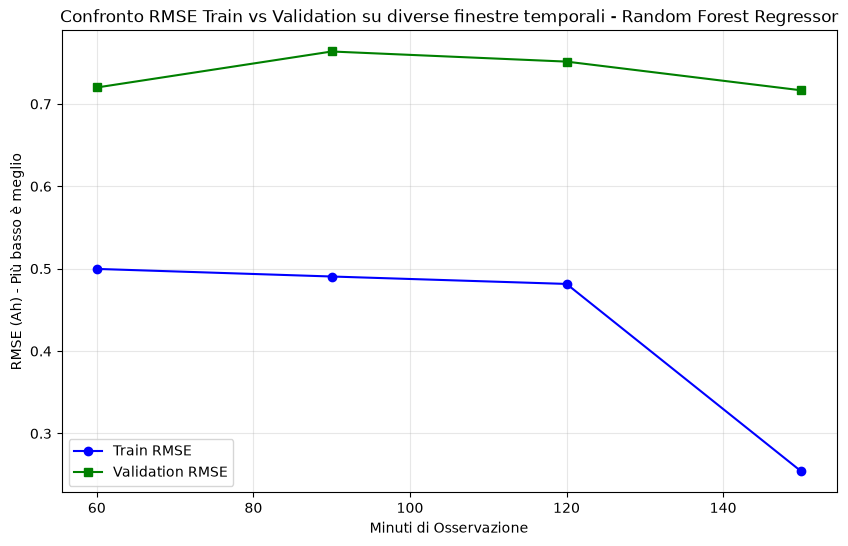

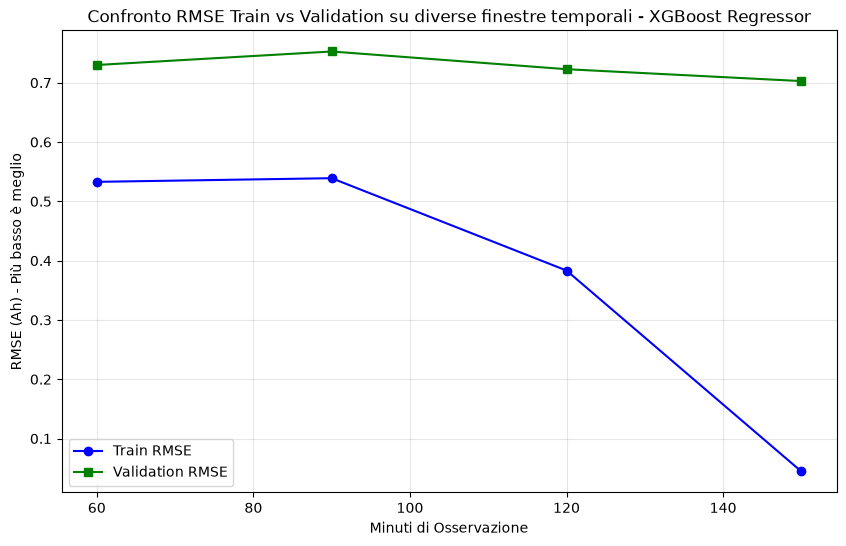

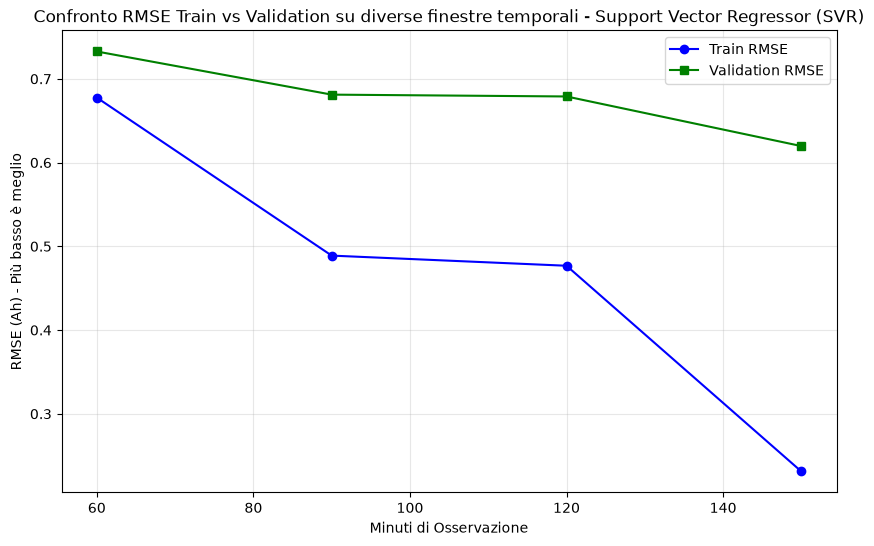

=== Random Forest Regressor ===
 -> Minimo teorico assoluto: 0.717 Ah
 -> Finestra ottima scelta (con compromesso): 60 minuti (RMSE: 0.720 Ah)

=== XGBoost Regressor ===
 -> Minimo teorico assoluto: 0.703 Ah
 -> Finestra ottima scelta (con compromesso): 120 minuti (RMSE: 0.723 Ah)

=== Support Vector Regressor (SVR) ===
 -> Minimo teorico assoluto: 0.620 Ah
 -> Finestra ottima scelta (con compromesso): 150 minuti (RMSE: 0.620 Ah)

Selected index for best model Random Forest Regressor: 0
Selected index for best model XGBoost Regressor: 2
Selected index for best model Support Vector Regressor (SVR): 3


In [101]:
ARR_MINUTI_OSSERVAZIONE = [60,90,120,150]

rmse_train_list = []
rmse_val_list = []
modelli_reg_ottimi_list = []
feature_reg_selezionate_list = []
for timespan in ARR_MINUTI_OSSERVAZIONE:
    print(f"\n=== Analisi per finestra di osservazione: {timespan} minuti ===")
    modelli_reg_ottimi_tmp, feature_reg_selezionate_tmp, rmse_train_list_tmp, rmse_val_list_tmp = tune_and_diagnose_regression(
        cut_off_minute=timespan,
        battery_dict=battery_dict,
        summary_train_df=summary_train_df,
        file_train_val=file_train_val
    )
    rmse_train_list.append(rmse_train_list_tmp)
    rmse_val_list.append(rmse_val_list_tmp)
    modelli_reg_ottimi_list.append(modelli_reg_ottimi_tmp)
    feature_reg_selezionate_list.append(feature_reg_selezionate_tmp)

# Compare the RMSE values across different observation windows
# this should be done for each model
for model_name in modelli_regressione.keys():
    train_rmse = [rmse_train[model_name] for rmse_train in rmse_train_list]
    val_rmse = [rmse_val[model_name] for rmse_val in rmse_val_list]
    plt.figure(figsize=(10, 6))
    plt.plot(ARR_MINUTI_OSSERVAZIONE, train_rmse, marker='o', label='Train RMSE', color='blue')
    plt.plot(ARR_MINUTI_OSSERVAZIONE, val_rmse, marker='s', label='Validation RMSE', color='green')
    plt.title(f"Confronto RMSE Train vs Validation su diverse finestre temporali - {model_name}")
    plt.xlabel("Minuti di Osservazione")
    plt.ylabel("RMSE (Ah) - Più basso è meglio")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

# Choose one of the observation windows based on the RMSE comparison for final testing
# The window should be the one with the lowest validation RMSE and acceptable train RMSE (to avoid overfitting)
#best_index = {}
final_regression_model = {}
final_feature_names = {}
'''for model_name in modelli_regressione.keys():
    best_index[model_name] = np.argmin([rmse_val[model_name] for rmse_val in rmse_val_list])
    best_observation_window = ARR_MINUTI_OSSERVAZIONE[best_index[model_name]]
    print(f"Best observation window for {model_name}: {best_observation_window} minutes")'''

# Impostiamo una tolleranza: quanti Ah siamo disposti a sacrificare per avere la predizione prima?
TOLLERANZA_AH = 0.025 

best_index = {}
for model_name in modelli_regressione.keys():
    # Estrarre la lista degli RMSE di validazione per il modello corrente
    val_rmse_vettore = [rmse_val[model_name] for rmse_val in rmse_val_list]
    
    # Trova il minimo assoluto (la tua vecchia euristica)
    min_rmse_assoluto = np.min(val_rmse_vettore)
    
    # Trova tutti gli indici in cui l'errore è vicino al minimo entro la tolleranza
    indici_accettabili = np.where(val_rmse_vettore <= (min_rmse_assoluto + TOLLERANZA_AH))[0]
    
    # Tra gli indici accettabili, prendiamo il PRIMO (ovvero la finestra temporale più BREVE/PRECOCE)
    best_index[model_name] = indici_accettabili[0]
    
    best_observation_window = ARR_MINUTI_OSSERVAZIONE[best_index[model_name]]
    rmse_scelto = val_rmse_vettore[best_index[model_name]]
    
    print(f"=== {model_name} ===")
    print(f" -> Minimo teorico assoluto: {min_rmse_assoluto:.3f} Ah")
    print(f" -> Finestra ottima scelta (con compromesso): {best_observation_window} minuti (RMSE: {rmse_scelto:.3f} Ah)\n")

for model_name, index in best_index.items():
    print(f"Selected index for best model {model_name}: {index}")
    final_regression_model[model_name] = modelli_reg_ottimi_list[index][model_name]
    final_feature_names[model_name] = feature_reg_selezionate_list[index]

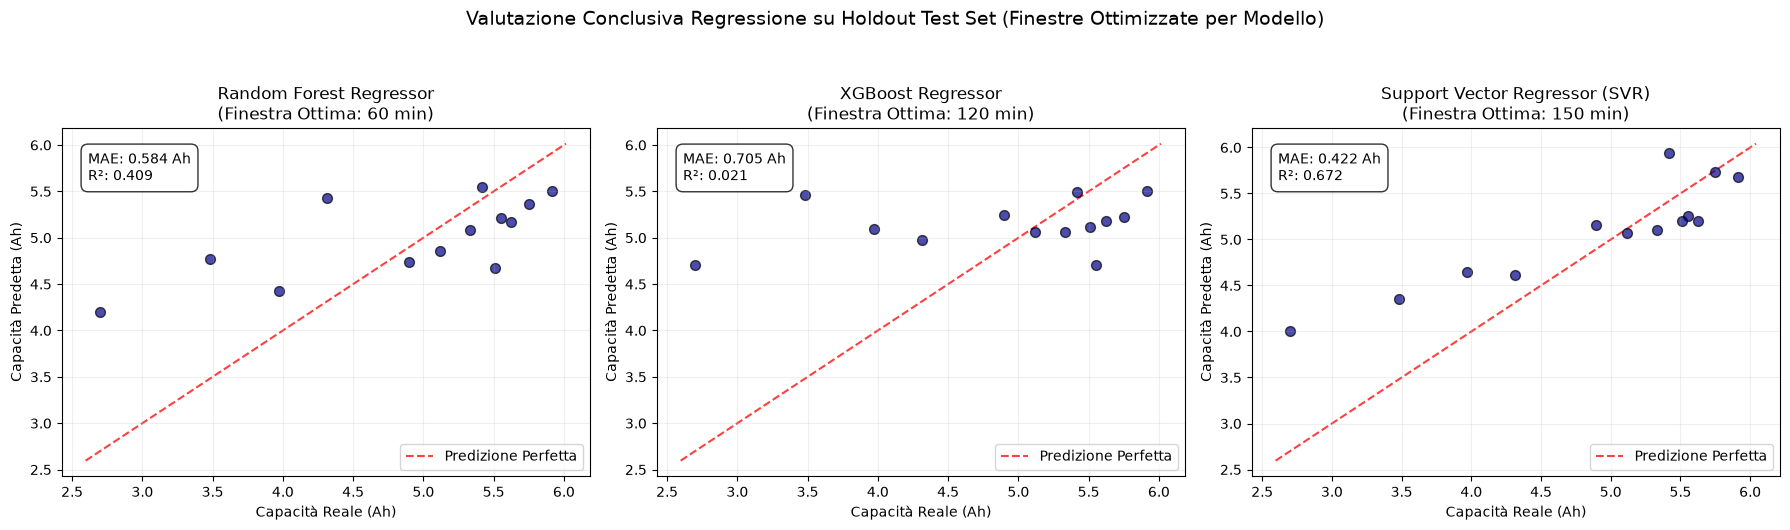

In [102]:
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt

# 2. Predizione e Plotting True vs Predicted (Inizializziamo la figura prima del ciclo)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Cicliamo in modo robusto su ciascun modello autonomamente
for idx, (name, pipeline_ottima) in enumerate(final_regression_model.items()):
    
    # CORREZIONE 1: Recuperiamo la finestra specifica ottimale per QUESTO modello
    model_best_window = ARR_MINUTI_OSSERVAZIONE[best_index[name]]
    # CORREZIONE 2: Recuperiamo la lista esatta delle feature estratte per QUELLA finestra
    model_feature_names = final_feature_names[name]
    
    # 1. Costruzione della matrice di TEST (Holdout) mirata sulla specifica finestra del modello
    test_regression_records = []
    for file_name in file_holdout_test:
        df_bat = battery_dict[file_name]
        y_val = summary_test_df[summary_test_df['file_name'] == file_name]['final_capacity'].values[0]
        
        # Estraiamo le feature storiche usando il cut-off ottimale del modello corrente
        # Usiamo le variabili globali AMPIEZZA_BLOCCO_MINUTI e NUMERO_LAG se definite, altrimenti valori nativi (10 e 3)
        base_w = AMPIEZZA_BLOCCO_MINUTI if 'AMPIEZZA_BLOCCO_MINUTI' in globals() else 10
        n_steps = NUMERO_LAG if 'NUMERO_LAG' in globals() else 3
        
        feat_reg = extract_regression_lagged_features(
            df_bat, base_window_min=base_w, steps=n_steps, end_minute=model_best_window
        )
        
        if feat_reg is not None:
            feat_reg['file_name'] = file_name
            feat_reg['target_capacity'] = y_val
            test_regression_records.append(feat_reg)
            
    # Se per motivi di lunghezza dei CSV l'holdout fallisse l'estrazione su finestre lunghe (es. 300 min)
    if not test_regression_records:
        print(f"⚠️ Attenzione: Impossibile estrarre dati di test per {name} alla finestra {model_best_window} min.")
        continue
        
    df_reg_test = pd.DataFrame(test_regression_records).bfill().ffill()
    
    # CORREZIONE 3: Estraiamo la matrice usando le feature specifiche salvate nel dizionario
    X_test_r = df_reg_test[model_feature_names].values
    y_test_r = df_reg_test['target_capacity'].values
    
    # Il modello è già addestrato e configurato, facciamo il predict
    y_pred_r = pipeline_ottima.predict(X_test_r)
    
    # Calcolo delle metriche di test reali
    mae = mean_absolute_error(y_test_r, y_pred_r)
    r2 = r2_score(y_test_r, y_pred_r)
    
    # Grafica sul sotto-plot del modello corrente
    ax = axes[idx]
    ax.scatter(y_test_r, y_pred_r, color='darkblue', alpha=0.7, edgecolors='k', s=50)
    
    # Linea di riferimento a 45 gradi
    lims = [min(y_test_r.min(), y_pred_r.min()) - 0.1, max(y_test_r.max(), y_pred_r.max()) + 0.1]
    ax.plot(lims, lims, 'r--', alpha=0.75, zorder=0, label="Predizione Perfetta")
    
    # Titolo dinamico che specifica anche quanti minuti sono serviti a quel modello
    ax.set_title(f"{name}\n(Finestra Ottima: {model_best_window} min)")
    ax.set_xlabel("Capacità Reale (Ah)")
    ax.set_ylabel("Capacità Predetta (Ah)")
    ax.grid(True, alpha=0.2)
    ax.text(0.05, 0.85, f"MAE: {mae:.3f} Ah\nR²: {r2:.3f}", 
            transform=ax.transAxes, bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))
    ax.legend(loc='lower right')

plt.suptitle("Valutazione Conclusiva Regressione su Holdout Test Set (Finestre Ottimizzate per Modello)", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

In [ ]:
# Preparazione dei Dati per la Regressione (Formato Sequenziale)
# Per la regressione (specialmente se userai modelli sequenziali come una
# Recurrent Neural Network o un MLP che legge la storia), hai bisogno di
# trasformare i dati della prima ora o due ore in sequenze o in vettori di
# feature aggregate dedicate alla regressione. Filtri i file di training sempre
# mantenendo il vincolo temporale ($t \le 60$ o $\le 120$ minuti).

In [ ]:
# Definizione delle Metriche di Regressione
# Prepari le funzioni per tracciare l'errore del modello: il
# Root Mean Squared Error (RMSE), il Mean Absolute Error (MAE) e l'R² score.

In [ ]:
# Configurazione dei Regressori e Training in Cross-Validation
# Usi lo stesso schema GroupKFold della Cella 7, ma applicato a modelli di regressione
# (es. RandomForestRegressor, LinearRegression, o la tua rete neurale).
# Il modello impara a mappare l'andamento della tensione della prima ora al valore
# numerico finale (es. 5.42 Ah). Calcoli l'errore Out-of-Fold.

In [ ]:
# Grafico di Performance della Regressione
# Plotti un grafico a dispersione (Scatter Plot) con il "Valore Reale di Capacità"
# sull'asse X e il "Valore Predetto" sull'asse Y per i dati di validazione.
# Più i punti sono vicini alla retta diagonale a 45°, più il tuo regressore
# precoce è preciso.

In [ ]:
# Test Finale (Holdout) della Regressione
# Prendi il modello di regressione definitivo, lo alleni su tutto il dataset
# di addestramento troncato alla finestra scelta e lo testi sui file di Holdout
# (anche loro bloccati a 1 o 2 ore) per calcolare l'errore finale reale su
# batterie mai viste.